In [ ]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
query_df = pd.read_csv("Data/query_formulation_df.csv")
serp_df = pd.read_csv("Data/logs_compiled.csv")
queries = pd.read_csv("Data/query_df.csv")
query_df["qid"] = [serp_df.loc[serp_df["serp_id"]==serp_id]["qid"].values[0] for serp_id in query_df["serp_id"]]
query_df["timestamp"] = [queries.loc[queries["qid"]==qid]["timestamp"].values[0] for qid in query_df["qid"]]
query_df = query_df[["uid","topic_number","qid","query", "timestamp", "serp_id", "precision@10"]]
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head(10)

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2
5,2,g3t2,q6,Qual è il nome del simbolo al centro della ban...,2026-05-19 15:05:41.521,serp6,0.4
6,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4
7,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,2026-05-19 15:09:06.317,serp7,0.4
8,3,g3t2,q12,qual è il nome del centro della bandiera indiana,2026-05-19 15:08:18.420,serp12,0.4
9,3,g3t1,q9,come si chiama il fiume sacro agli indiani,2026-05-19 14:50:09.786,serp9,0.4


In [ ]:
import language_tool_python
from Levenshtein import distance
from tqdm.notebook import tqdm
import spacy

nlp = spacy.load("it_core_news_lg")
tool = language_tool_python.LanguageTool('it')

corrected_query_list = []
num_typos = []
levenshtein_dist = []
lex_density = []
lex_diversity = []
ttr = []
stop_word_ratio = []
num_concepts = []


for _, row in tqdm(query_df.iterrows(), total=len(query_df)):
    query = row["query"]
    corrected_query = tool.correct(query)
    if query.lower() == corrected_query.lower():
        corrected_query_list.append("")
        num_typos.append(0)
    else:
        corrected_query_list.append(corrected_query)
        matches = tool.check(query)
        num_typos.append(len(matches))
    levenshtein_dist.append(distance(query.lower(), corrected_query.lower()))
    doc = nlp(query)

    lex_words = [] # lexical words, i.e., nouns, verbs, adjectives, and adverbs

    words = []

    # Extract noun chunks
    noun_phrases = [chunk.text for chunk in doc.noun_chunks]

    stop_word_count = 0
    for token in doc:
        # print(token.text, token.pos_, token.tag_)
        if token.pos_ in ["ADJ", "ADV", "NOUN", "PROPN", "VERB", "AUX"]:
            lex_words.append(token.text.strip().lower())
        if token.pos_ not in ["SYM", "X", "PUNCT"]:
            words.append(token.text.strip().lower())
        if token.is_stop:
            stop_word_count += 1

    lex_density.append(len(lex_words)/len(words))
    ttr.append(len(set(words))/len(words)) # type token ratio: num of unique words/total num of words
    lex_diversity.append(len(set(lex_words))/len(lex_words)) # lexical diversity: num of unique lexical words/total num of lexical words
    stop_word_ratio.append(stop_word_count/len(words))
    num_concepts.append(len(noun_phrases))
    # print(query, corrected_query, len(matches), distance(query, corrected_query))

query_df["lex_density"] = lex_density
query_df["lex_diversity"] = lex_diversity
query_df["ttr"] = ttr
query_df["stop_word_ratio"] = stop_word_ratio
query_df["corrected_query"] = corrected_query_list
query_df["num_typos"] = num_typos
query_df["levenshtein_dist"] = levenshtein_dist
query_df["num_concepts"] = num_concepts

  0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
query_df_sample = query_df.sample(5, random_state=67).sort_index()
query_df_sample

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,lex_density,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7,0.5,1.0,1.0,0.500000,,0,0,3
25,5,g3t2,q32,Bandiera,2026-05-19 15:21:16.565,serp32,0.3,1.0,1.0,1.0,0.000000,,0,0,1
38,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8,1.0,1.0,1.0,0.000000,,0,0,2
77,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,2026-05-19 10:44:45.385,serp91,0.3,0.5,1.0,1.0,0.666667,,0,0,3
99,18,g3t2,q117,Simbolo della bandiera dell'india,2026-05-19 15:13:42.292,serp117,0.9,0.6,1.0,1.0,0.400000,,0,0,3


In [ ]:
serp_df = pd.read_csv("Data/logs_compiled.csv")
serp_df.loc[serp_df["serp_id"]=="serp117"]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp
928,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://sullestradedelmondo.it/bandiera-indiana/,"Bandiera Indiana: significato, storia e curiosità","\n May 21, 2022 ... Significato dei c...",1.0,1,0,2026-05-19 15:13:43.391
929,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://mastroviaggiatore.it/saree/blog/lindia...,"L'INDIA A COLORI, I COLORI DELL'INDIA - MASTRO...","\n Feb 14, 2025 ... L'elemento più im...",2.0,1,0,2026-05-19 15:13:43.393
930,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.bandiere-nazionali.com/bandiera-in...,Bandiera di India,\n La bandiera nazionale dell'India è...,3.0,1,0,2026-05-19 15:13:43.394
931,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://liceoberchet.edu.it/ricerche/geo4d_03/...,India Britannica,\n ... dell'Ordine della stella dell'...,4.0,1,0,2026-05-19 15:13:43.396
932,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.skuola.net/geografia-medie/india-d...,"L'India: un viaggio tra cultura, geografia e t...","\n Jun 28, 2014 ... La bandiera india...",5.0,1,0,2026-05-19 15:13:43.398
933,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://it.gov-civ-guarda.pt/flag-india,"Bandiera dell'India | Storia, design e signifi...","\n Bandiera dell'India, bandiera a st...",6.0,1,1,2026-05-19 15:13:43.399
934,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.focus.it/ambiente/animali/8-cose-c...,8 cose che (forse) non sai sulle vacche sacre ...,"\n Mar 31, 2019 ... Piuttosto, vi ved...",7.0,0,0,2026-05-19 15:13:43.401
935,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://flags-world.com/it/bandiera-india-colo...,Bandiera India: colori e storia - Flags-World,"\n Jan 4, 2021 ... Successivamente, i...",8.0,1,0,2026-05-19 15:13:43.403
936,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://dinolingo.com/it/hindi-culture-hindi-c...,"Alla scoperta dell'India: cultura, geografia, ...","\n Apr 9, 2017 ... La bandiera ricord...",9.0,1,0,2026-05-19 15:13:43.404
937,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.wisdomlib.org/it/concept/dharmacakra,Dharmacakra: Simbolismo e significato,"\n Apr 24, 2026 ... La ruota della le...",10.0,1,0,2026-05-19 15:13:43.406


In [ ]:
relevance = pd.read_csv("Data/relevance.csv")

relevance.loc[relevance["doc"]==serp_df.iloc[932]["url"]]

,topic_number,topic,doc,relevance
29,g3t2,Bandiera India simbolo,https://www.skuola.net/geografia-medie/india-d...,1


In [ ]:
from driver import get_text_stats
text_stat_results = get_text_stats(query_df, "query")

query_df["query_len"] = text_stat_results["content_len"]
query_df["mean_aoa"] = text_stat_results["mean_aoa"]
query_df["mean_conc"] = text_stat_results["mean_conc"]
query_df["gulpease_index"] = text_stat_results["gulpease_index"]


  0%|          | 0/103 [00:00<?, ?it/s]

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
query_df["effective_query"] = [int(p10 >= 0.8) for p10 in query_df["precision@10"]]
query_df.loc[query_df["effective_query"]==1]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,lex_density,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,query_len,mean_aoa,mean_conc,gulpease_index,effective_query
17,4,g3t1,q18,Fiume sacro indiano,2026-05-19 15:20:20.872,serp18,0.8,1.000000,1.0,1.0,0.000000,,0,0,1,3,4.80,7.50,132.333333,1
30,6,g3t2,q38,Simbolo andiera India,2026-05-19 15:09:52.643,serp38,0.8,1.000000,1.0,1.0,0.000000,Simbolo bandiera India,1,1,2,3,6.60,NaN,125.666667,1
34,7,g3t2,q39,il simbolo della baniera dell dell'india,2026-05-19 14:52:29.403,serp39,0.8,0.428571,1.0,1.0,0.571429,Il simbolo della Baviera dell'india,3,6,3,6,6.60,NaN,80.666667,1
35,7,g3t2,q40,il simbolo della baniera dell dell'india,2026-05-19 14:53:01.273,serp40,0.8,0.428571,1.0,1.0,0.571429,Il simbolo della Baviera dell'india,3,6,3,6,6.60,NaN,80.666667,1
37,8,g3t2,q51,Bandira india simbolo,2026-05-19 15:14:06.749,serp51,0.8,1.000000,1.0,1.0,0.000000,Bandirà india simbolo,1,1,2,3,6.60,NaN,125.666667,1
38,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8,1.000000,1.0,1.0,0.000000,,0,0,2,3,4.80,7.50,139.000000,1
39,8,g3t1,q52,Fiume sacro India,2026-05-19 15:16:00.828,serp52,0.8,1.000000,1.0,1.0,0.000000,,0,0,2,3,4.80,7.50,139.000000,1
40,8,g3t2,q50,centro bandiera india simbolo,2026-05-19 15:11:39.971,serp50,0.9,1.000000,1.0,1.0,0.000000,,0,0,1,4,5.78,7.85,99.000000,1
99,18,g3t2,q117,Simbolo della bandiera dell'india,2026-05-19 15:13:42.292,serp117,0.9,0.600000,1.0,1.0,0.400000,,0,0,3,4,5.78,7.85,89.000000,1


In [ ]:
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head()

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,lex_density,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,query_len,mean_aoa,mean_conc,gulpease_index,effective_query
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2,0.500000,1.0,1.0,0.375000,,0,0,3,8,NaN,NaN,79.000000,0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1,0.545455,1.0,1.0,0.545455,Quale è il nome del simbolo al centro della ba...,1,1,6,11,5.12,5.3,69.909091,0
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4,0.750000,1.0,1.0,0.250000,,0,0,2,4,4.80,7.5,109.000000,0
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7,0.500000,1.0,1.0,0.500000,,0,0,3,5,NaN,NaN,95.000000,0
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2,0.500000,1.0,1.0,0.375000,,0,0,3,7,NaN,NaN,83.285714,0


In [ ]:
import pandas as pd

query_df = pd.read_csv("Data/query_formulation_df.csv")

query_df.loc[query_df["uid"]==5]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,lex_density,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,query_len,mean_aoa,mean_conc,gulpease_index,effective_query
18,5,g3t1,q23,come si chiama il fiume sacro agli indiani,2026-05-19 14:54:34.881,serp23,0.4,0.625000,1.0,1.0,0.500000,NaN,0,0,2,8,4.80,7.50,82.750000,0
19,5,g3t2,q30,Qual eil simbolo della bandiera india,2026-05-19 15:19:12.025,serp30,0.4,0.666667,1.0,1.0,0.166667,Qual El simbolo della bandiera india,1,1,1,6,5.78,7.85,85.666667,0
20,5,g3t1,q22,come si chiama il fiume sacro agli indiani,2026-05-19 14:52:58.725,serp22,0.4,0.625000,1.0,1.0,0.500000,NaN,0,0,2,8,4.80,7.50,82.750000,0
21,5,g3t3,q27,Quali sono 5 animali tipici dell india,2026-05-19 15:02:30.582,serp27,0.2,0.571429,1.0,1.0,0.428571,NaN,0,0,3,7,NaN,NaN,86.142857,0
22,5,g3t2,q31,Qual eil simbolo della bandiera india,2026-05-19 15:20:59.385,serp31,0.4,0.666667,1.0,1.0,0.166667,Qual El simbolo della bandiera india,1,1,1,6,5.78,7.85,85.666667,0
23,5,g3t1,q19,Come si chiama il fiume,2026-05-19 14:50:30.668,serp19,0.4,0.600000,1.0,1.0,0.600000,NaN,0,0,1,5,4.80,7.50,111.000000,0
24,5,g3t3,q28,Quali sono 5 animali tipici dell india,2026-05-19 15:08:15.219,serp28,0.2,0.571429,1.0,1.0,0.428571,NaN,0,0,3,7,NaN,NaN,86.142857,0
25,5,g3t2,q32,Bandiera,2026-05-19 15:21:16.565,serp32,0.3,1.000000,1.0,1.0,0.000000,NaN,0,0,1,1,4.96,7.85,309.000000,0


In [ ]:
query_df["query"][0]

'Quali sono i cinque animali tipici dell india'

In [ ]:

print(noun_phrases)
# Output: ['La bella città', 'Roma', 'molti turisti', 'ogni anno']

['Quali', 'cinque tipici animali', 'l india']


### Visualisation

In [ ]:
import pandas as pd
from driver import get_boxplots, get_radar_plot

sig_test_results = pd.read_csv("Data/sig_test_query_formulation.csv")

query_df = pd.read_csv("Data/query_formulation_df.csv")
categories = ["lex_density", "mean_aoa",
              "gulpease_index",  
            #   "lex_diversity", 
            #   "ttr", 
               "num_typos", "levenshtein_dist", "query_len", "stop_word_ratio", "mean_conc", "num_concepts"]

In [ ]:
from driver import get_significance

sig_test_results = get_significance(df=query_df, performance_metric="precision@10", threshold=0.8, stage="query_formulation", categories=categories)
sig_test_results.to_csv("Data/sig_test_query_formulation.csv", index=False, encoding="utf8")
sig_test_results

,search_stage,feature,feature_mean_val_diff,pval,significant
0,query_formulation,lex_density,-0.322026,0.0002,True
1,query_formulation,mean_aoa,-0.839566,0.0652,False
2,query_formulation,gulpease_index,-23.426193,0.0944,False
3,query_formulation,num_typos,-0.559102,0.0698,False
4,query_formulation,levenshtein_dist,-1.172577,0.0182,True
5,query_formulation,query_len,4.121749,0.0002,True
6,query_formulation,stop_word_ratio,0.313759,0.0002,True
7,query_formulation,mean_conc,-1.150714,0.1224,False
8,query_formulation,num_concepts,0.633570,0.1786,False


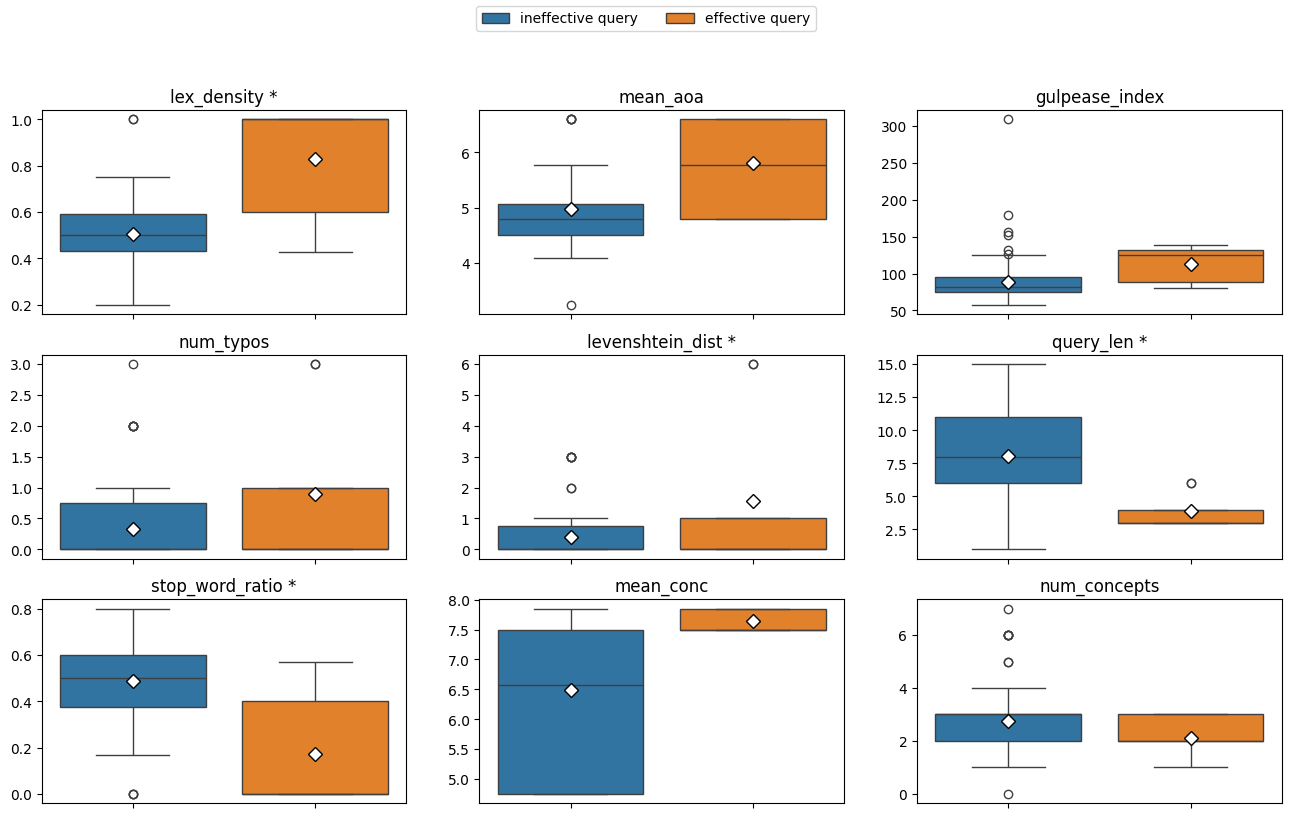

In [ ]:
get_boxplots(query_df, "query_formulation", categories, "effective_query", artefact="query", n_cols=3, n_rows=3, stats_df=sig_test_results)

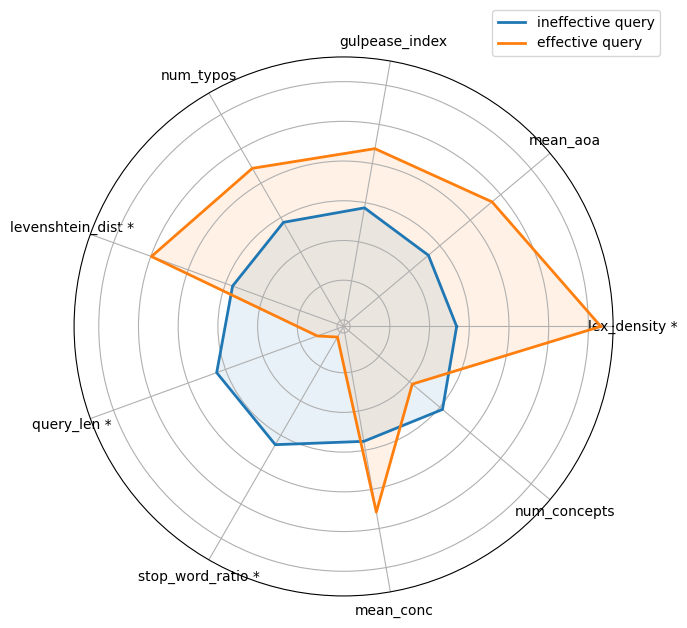

In [ ]:
get_radar_plot(query_df, "query_formulation", categories, artefact="query", group="effective_query", normalized=True, stats_df=sig_test_results)